In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import qmc

In [2]:
from HSA_Mo_C_001_pyro import (
    kinetics_model,
    bayesian_model,
    TRUE_PARAMS,
    calculate_partial_pressures,
    generate_synthetic_data,
    run_variational_inference,
    run_inference,
    predict,
    sample_prior,
    sample_posterior,
)

In [3]:
T_range = np.array([450, 600])
p_range = np.array([3, 9])
c2h_range = np.array([0.2, 4])
c2m_range = np.array([0.5, 1000])
c2w_range = np.array([0.5, 1000])
c2i_range = np.array([0.05, 1])

In [4]:
n_obs = 98
sampler = qmc.LatinHypercube(d=6)
sample = sampler.random(n=n_obs)

# Scale samples to the appropriate ranges
T_lhs = qmc.scale(sample[:, 0:1], T_range[0], T_range[1])
p_lhs = qmc.scale(sample[:, 1:2], p_range[0], p_range[1])
c2h_lhs = qmc.scale(sample[:, 2:3], c2h_range[0], c2h_range[1])
c2m_lhs = qmc.scale(sample[:, 3:4], c2m_range[0], c2m_range[1])
c2w_lhs = qmc.scale(sample[:, 4:5], c2w_range[0], c2w_range[1])
c2i_lhs = qmc.scale(sample[:, 5:6], c2i_range[0], c2i_range[1])

proposals = np.column_stack([T_lhs, p_lhs, c2h_lhs, c2m_lhs, c2w_lhs, c2i_lhs])
print(proposals.shape)

(98, 6)


In [5]:
Ts = torch.tensor(proposals[:, 0]).reshape(-1, 1)
ps = torch.tensor(proposals[:, 1]).reshape(-1, 1)
c2hs = torch.tensor(proposals[:, 2]).reshape(-1, 1)
c2ms = torch.tensor(proposals[:, 3]).reshape(-1, 1)
c2ws = torch.tensor(proposals[:, 4]).reshape(-1, 1)
c2is = torch.tensor(proposals[:, 5]).reshape(-1, 1)
pi = calculate_partial_pressures(ps, c2hs, c2ms, c2ws, c2is)

In [6]:
T, pi, r_obs = generate_synthetic_data(Ts, ps, c2hs, c2ms, c2ws, c2is, 0.01)
T, pi, r_obs_true = generate_synthetic_data(Ts, ps, c2hs, c2ms, c2ws, c2is, 0.0)
print(r_obs.shape)

torch.Size([10, 98, 1, 1])


In [7]:
prior_idata = sample_prior(num_samples=1000)
r_prior = predict(prior_idata, T, pi, num_samples=6, key="prior")
print(r_prior.shape)

(10, 98, 1, 6)


In [8]:
display(prior_idata)

Inference data with groups:
	> prior

array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'Ea_deact'}>,
        <Axes: title={'center': 'n_deact'}>,
        <Axes: title={'center': 'sigma_r'}>]], dtype=object)

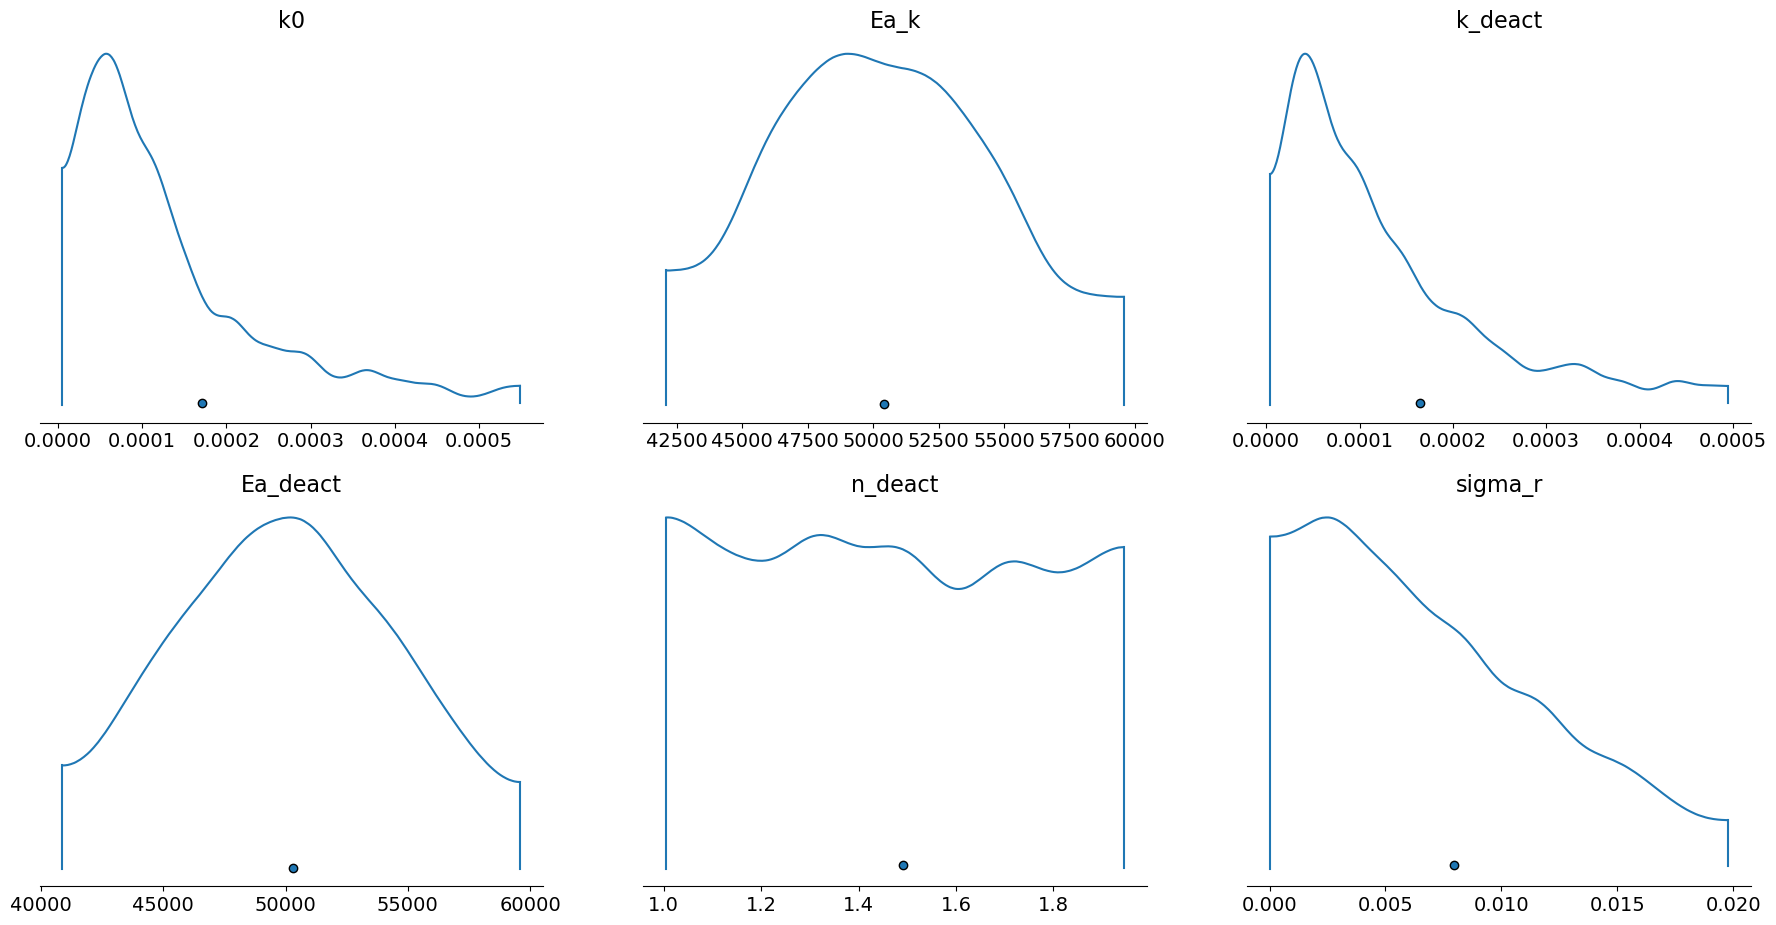

In [9]:
import arviz as az

az.plot_density(
    prior_idata,
    group="prior",
    var_names=[
        "k0",
        "Ea_k",
        "k_deact",
        "Ea_deact",
        "n_deact",
        "sigma_r",
    ],
)

In [10]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_obs_true[:, i, 0, 0], "go", label="True data")
    plt.plot(r_prior.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        np.arange(r_prior.shape[0]),
        np.quantile(r_prior[:, i, 0, :], 0.05, axis=1),
        np.quantile(r_prior[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=97), Output()), _dom_classes=('w…

In [11]:
print("r_obs.shape:", r_obs.shape)
print("T.shape:", T.shape)
print("pi.shape:", pi.shape)

r_obs.shape: torch.Size([10, 98, 1, 1])
T.shape: torch.Size([98, 1])
pi.shape: torch.Size([98, 5])


In [12]:
Vidata = run_variational_inference(T, pi, r_obs, num_steps=5000, learning_rate=0.01)

Starting SVI: 5000 optimization steps
  Step 10/5000, Loss: 1.00e+07
  Step 20/5000, Loss: 9.38e+06
  Step 30/5000, Loss: 3.99e+06
  Step 40/5000, Loss: 3.97e+06
  Step 50/5000, Loss: 3.72e+06
  Step 60/5000, Loss: 1.53e+06
  Step 70/5000, Loss: 3.01e+06
  Step 80/5000, Loss: 1.33e+06
  Step 90/5000, Loss: 5.80e+05
  Step 100/5000, Loss: 2.00e+06
  Step 110/5000, Loss: 1.56e+06
  Step 120/5000, Loss: 4.34e+05
  Step 130/5000, Loss: 8.37e+05
  Step 140/5000, Loss: 6.58e+05
  Step 150/5000, Loss: 9.03e+05
  Step 160/5000, Loss: 3.88e+05
  Step 170/5000, Loss: 4.48e+05
  Step 180/5000, Loss: 1.77e+05
  Step 190/5000, Loss: 3.72e+05
  Step 200/5000, Loss: 4.89e+05
  Step 210/5000, Loss: 5.49e+05
  Step 220/5000, Loss: 1.60e+05
  Step 230/5000, Loss: 4.17e+05
  Step 240/5000, Loss: 1.88e+05
  Step 250/5000, Loss: 2.67e+05
  Step 260/5000, Loss: 2.05e+05
  Step 270/5000, Loss: 2.39e+05
  Step 280/5000, Loss: 1.73e+05
  Step 290/5000, Loss: 1.75e+05
  Step 300/5000, Loss: 9.33e+04
  Step 310/

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning: the default dims 'chain' and 'draw' will be added automatically
  warnings.warn(


Reason: The size of tensor a (4000) must match the size of tensor b (98) at non-singleton dimension 1
  Trace Shapes:                
   Param Sites:                
  Sample Sites:                
      t_k0 dist 4000 1 |       
          value 4000 1 |       
    t_Ea_k dist 4000 1 |       
          value 4000 1 |       
 t_k_deact dist 4000 1 |       
          value 4000 1 |       
t_Ea_deact dist 4000 1 |       
          value 4000 1 |       
        k0 dist 4000 1 | 4000 1
          value        | 4000 1
      Ea_k dist 4000 1 | 4000 1
          value        | 4000 1
   k_deact dist 4000 1 | 4000 1
          value        | 4000 1
  Ea_deact dist 4000 1 | 4000 1
          value        | 4000 1
   n_deact dist 4000 1 |       
          value 4000 1 |       
   sigma_r dist 4000 1 |       
          value 4000 1 |       
Approximate posterior created with 4000 samples



In [13]:
sample_posterior(
    Vidata,
    T,
    pi,
    num_samples=16,
)

torch.Size([98, 1]) torch.Size([98, 5]) None


Inference data with groups:
	> posterior_predictive

In [14]:
run_inference(
    T,
    pi,
    r_obs,
    num_samples=100,
    num_warmup=5,
    num_chains=4,
)

Starting MCMC: 4 chains × (5 warmup + 100 samples)


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\pyro\poutine\subsample_messenger.py:70: TracerWarning: torch.tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  result = torch.tensor(0.0, device=self.device)


MCMC sampling completed successfully!


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\io_pyro.py:158: UserWarning: Could not get vectorized trace, log_likelihood group will be omitted. Check your model vectorization or set log_likelihood=False
  warnings.warn(


Inference data with groups:
	> posterior
	> posterior_predictive
	> sample_stats
	> observed_data

In [23]:
from pyro.infer.mcmc import MCMC, HMC, NUTS

nuts_kernel = NUTS(bayesian_model, target_accept_prob=0.9, jit_compile=True)

mcmc = MCMC(
    nuts_kernel,
    num_samples=400,
    warmup_steps=100,
    num_chains=4,
)
mcmc.run(T, pi, r_obs)
idata = az.from_pyro(mcmc)

Warmup [1]:   0%|          | 0/500 [00:00, ?it/s]

Warmup [2]:   0%|          | 0/500 [00:00, ?it/s]

Warmup [3]:   0%|          | 0/500 [00:00, ?it/s]

Warmup [4]:   0%|          | 0/500 [00:00, ?it/s]

KeyboardInterrupt: 

In [20]:
r_pred = predict(Vidata, T, pi, num_samples=1000)

In [21]:
@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_pred.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        np.arange(r_pred.shape[0]),
        np.quantile(r_pred[:, i, 0, :], 0.05, axis=1),
        np.quantile(r_pred[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )
    print(proposals[i, :])

interactive(children=(IntSlider(value=0, description='Observation Index', max=97), Output()), _dom_classes=('w…

array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'k_deact'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'Ea_deact'}>,
        <Axes: title={'center': 'Ea_deact'}>],
       [<Axes: title={'center': 'n_deact'}>,
        <Axes: title={'center': 'n_deact'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>]], dtype=object)

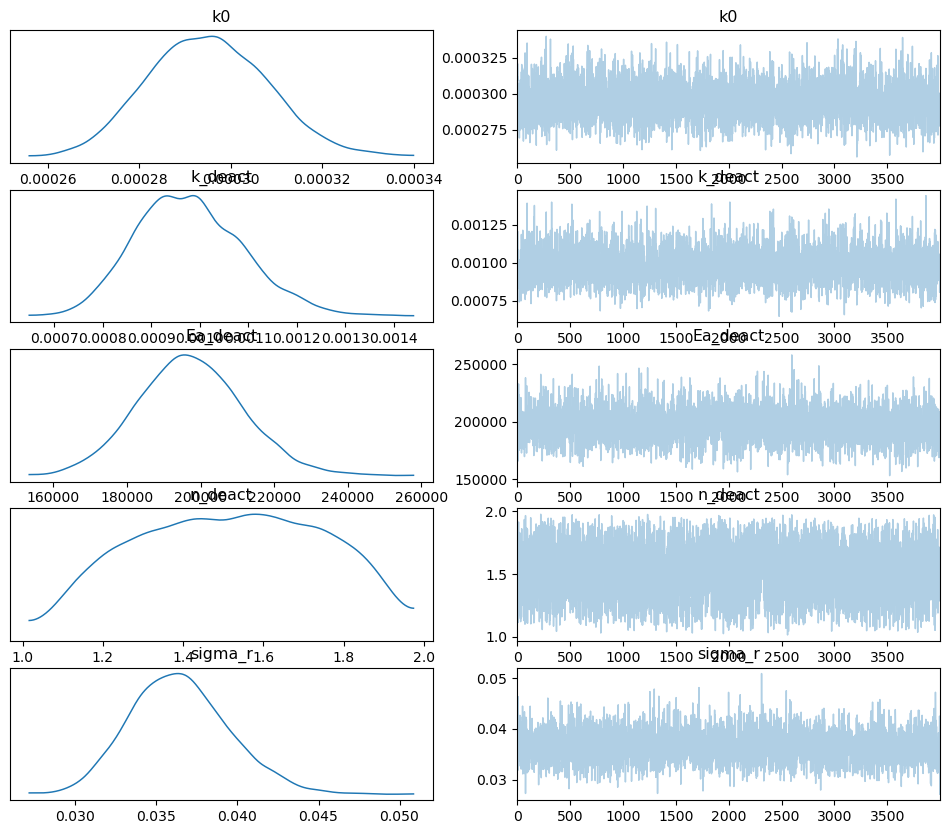

In [22]:
import arviz as az

az.plot_trace(
    Vidata,
    var_names=[
        "k0",
        # "Ea_k",
        "k_deact",
        "Ea_deact",
        "n_deact",
        "sigma_r",
    ],
)

In [19]:
az.summary(
    Vidata, var_names=["k0", "Ea_k", "k_deact", "Ea_deact", "n_deact", "sigma_r"]
)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0,0.000,0.000,0.000,0.000,0.000,0.000,3880.0,3880.0,NaN
Ea_k,72868.562,1486.577,70136.523,75598.789,23.680,16.393,3940.0,3772.0,NaN
k_deact,0.001,0.000,0.001,0.001,0.000,0.000,3847.0,3800.0,NaN
Ea_deact,197222.688,14224.788,169752.391,222767.688,223.118,164.717,4064.0,3958.0,NaN
n_deact,1.516,0.225,1.127,1.901,0.004,0.002,3407.0,3866.0,NaN
sigma_r,0.036,0.003,0.031,0.042,0.000,0.000,3829.0,3694.0,NaN
